# Block 1 — Python / Pandas / NumPy Essentials

**Target: 2 hours. Real data: UCI Bank Marketing.**

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=next((p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/"reference"/"dataset_loader.py").exists()),Path.cwd())
sys.path.insert(0,str(ROOT/"reference"))
from dataset_loader import load_checked_csv
URL="https://raw.githubusercontent.com/Rawanmalharbi/UCI-Bank-Marketing/main/bank-full.csv"
df=load_checked_csv("bank_full.csv",URL,expected_cols=["age","job","marital","education","balance","day","month","duration","campaign","pdays","previous","poutcome","y"],min_rows=45000,read_csv_kwargs={"sep":";"})
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## A. Audit
Report shape, dtypes, missing, duplicates, unique counts, target (`y`) balance and numeric summary.

In [21]:
df.shape
df.dtypes
df.isna().sum() # no missing
df.duplicated().sum()  # no duplicate

display(df.age.value_counts().sort_index(ascending=False))
display(df.nunique().sort_values())
display(df['y'].value_counts(normalize=True)) # !!!

df.describe()

age
95      2
94      1
93      2
92      2
90      2
     ... 
22    129
21     79
20     50
19     35
18     12
Name: count, Length: 77, dtype: int64

housing         2
loan            2
default         2
y               2
contact         3
marital         3
poutcome        4
education       4
month          12
job            12
day            31
previous       41
campaign       48
age            77
pdays         559
duration     1573
balance      7168
dtype: int64

y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


## B. Filtering
1. Count age > 50 and balance < 0.
2. Among age > 60, fraction with y == yes.
3. Show 20 largest balances among people under 30.

In [ ]:
df.loc[(df['age'] > 50) & (df['balance'] < 0)].shape[0]  # how many rows

df.query("age > 60")['y'].value_counts(normalize=True)

df.query("age < 30")[['age', 'balance']].sort_values(by='balance', ascending=False).head(20)



,age,balance
34170,29,36252
2554,28,26765
2343,26,24299
41922,27,24025
31124,24,23878
39535,24,23878
29521,26,23494
7014,28,22171
38992,29,22171
6876,29,22008


## C. Groupby / agg / transform
One row per job: count, mean age, median balance, subscription rate. Then add job-mean and demeaned balance.

In [64]:
new_df = df.assign(target=(df['y']=='yes').astype(int))  # y: subscription yes or no
# now turned into 1 and 0

job_summary = new_df.groupby('job').agg(
    size=("job", "size"),
    mean_age=('age', 'mean'),
    median_b = ('balance', 'median'),
    sub_rate = ('target', 'mean')
)
display(job_summary)

new_df['job_mean_b'] = new_df.groupby('job')['balance'].transform('mean')  # !!!
new_df['demeaned_b'] = new_df['balance'] - new_df['job_mean_b']
new_df[['job', 'balance', 'job_mean_b', 'demeaned_b']]

,size,mean_age,median_b,sub_rate
job,,,,
admin.,5171,39.289886,396.0,0.122027
blue-collar,9732,40.044081,388.0,0.072750
entrepreneur,1487,42.190989,352.0,0.082717
housemaid,1240,46.415323,406.0,0.087903
management,9458,40.449567,572.0,0.137556
retired,2264,61.626767,787.0,0.227915
self-employed,1579,40.484484,526.0,0.118429
services,4154,38.740250,339.5,0.088830
student,938,26.542644,502.0,0.286780


,job,balance,job_mean_b,demeaned_b
0,management,2143,1763.616832,379.383168
1,technician,29,1252.632092,-1223.632092
2,entrepreneur,2,1521.470074,-1519.470074
3,blue-collar,1506,1078.826654,427.173346
4,unknown,1,1772.357639,-1771.357639
...,...,...,...,...
45206,technician,825,1252.632092,-427.632092
45207,retired,1729,1984.215106,-255.215106
45208,retired,5715,1984.215106,3730.784894
45209,blue-collar,668,1078.826654,-410.826654


## D. Merge
Merge the job summary back using correct `validate=` and verify row count.

In [78]:
merged = df.merge(job_summary,on="job",how="left",validate="m:1")
joined = df.join(job_summary, on='job', how='left')
display(merged)

False in (joined == merged).values  # False, so merged and joined are equal

,age,job,marital,education,default,balance,housing,loan,contact,day,...,duration,campaign,pdays,previous,poutcome,y,size,mean_age,median_b,sub_rate
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,...,261,1,-1,0,unknown,no,9458,40.449567,572.0,0.137556
1,44,technician,single,secondary,no,29,yes,no,unknown,5,...,151,1,-1,0,unknown,no,7597,39.314598,421.0,0.110570
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,...,76,1,-1,0,unknown,no,1487,42.190989,352.0,0.082717
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,...,92,1,-1,0,unknown,no,9732,40.044081,388.0,0.072750
4,33,unknown,single,unknown,no,1,no,no,unknown,5,...,198,1,-1,0,unknown,no,288,47.593750,677.0,0.118056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,...,977,3,-1,0,unknown,yes,7597,39.314598,421.0,0.110570
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,...,456,2,-1,0,unknown,yes,2264,61.626767,787.0,0.227915
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,...,1127,5,184,3,success,yes,2264,61.626767,787.0,0.227915
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,...,508,4,-1,0,unknown,no,9732,40.044081,388.0,0.072750


False

## E. Pivot / melt
Pivot subscription rate by job × marital status, then melt to long form.

In [90]:
print("Each value in this pivot table is a sub_rate")
p = pd.pivot_table(
    new_df, index='job', columns='marital', values='target', aggfunc='mean'
)
display(p)

print("After reset_index, use 'job' as the identifier var, " \
"while the other cols ('divorced', 'married', 'single') become values " \
"that are paired with the values of sub_rate"
)
molten = p.reset_index().melt(
    id_vars='job', var_name='marital', value_name='sub_rate'
)
display(molten.head(15))

Each value in this pivot table is a sub_rate


marital,divorced,married,single
job,,,
admin.,0.120000,0.113628,0.135995
blue-collar,0.077333,0.062715,0.105760
entrepreneur,0.083799,0.075701,0.113445
housemaid,0.097826,0.073465,0.166667
management,0.127813,0.126111,0.162199
retired,0.284706,0.220682,0.120370
self-employed,0.157143,0.079557,0.192825
services,0.091075,0.073951,0.117696
student,0.166667,0.185185,0.293850


After reset_index, use 'job' as the identifier var, while the other cols ('divorced', 'married', 'single') become values that are paired with the values of sub_rate


,job,marital,sub_rate
0,admin.,divorced,0.120000
1,blue-collar,divorced,0.077333
2,entrepreneur,divorced,0.083799
3,housemaid,divorced,0.097826
4,management,divorced,0.127813
5,retired,divorced,0.284706
6,self-employed,divorced,0.157143
7,services,divorced,0.091075
8,student,divorced,0.166667
9,technician,divorced,0.083243


## F. Cyclic month
Map month names to 1–12 and build sine/cosine.

In [96]:
month_map=dict(
    zip(["jan","feb","mar","apr","may","jun",
         "jul","aug","sep","oct","nov","dec"],
         range(1,13)
    )
)

m = df["month"].map(month_map) # words into numbers
display(m)
month_sin=np.sin(2 * np.pi * m / 12)
month_cos=np.cos(2 * np.pi * m / 12)
display(pd.DataFrame({"month":df["month"].head(),"sin":month_sin.head(),"cos":month_cos.head()}))


0         5
1         5
2         5
3         5
4         5
         ..
45206    11
45207    11
45208    11
45209    11
45210    11
Name: month, Length: 45211, dtype: int64

,month,sin,cos
0,may,0.5,-0.866025
1,may,0.5,-0.866025
2,may,0.5,-0.866025
3,may,0.5,-0.866025
4,may,0.5,-0.866025


## G. Weird/missing categories
Count `unknown` values by categorical column; build compact audit table.

In [130]:
obj = df.select_dtypes(include='object').columns
display(obj)

display(pd.Series(
    {c : (df[c]=='unknown').sum() for c in obj}, name='num_unknown'
))

pd.DataFrame({
    "Category": [c for c in obj],
    "Unknown number": [(df[c]=='unknown').sum() for c in obj],
    "Unknown perc": [(df[c]=='unknown').mean() for c in obj]
})

C:\Users\Startklar\AppData\Local\Temp\ipykernel_48864\3473961819.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj = df.select_dtypes(include='object').columns


Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'y'],
      dtype='str')

job            288
marital          0
education     1857
default          0
housing          0
loan             0
contact      13020
month            0
poutcome     36959
y                0
Name: num_unknown, dtype: int64

,Category,Unknown number,Unknown perc
0,job,288,0.006370
1,marital,0,0.000000
2,education,1857,0.041074
3,default,0,0.000000
4,housing,0,0.000000
5,loan,0,0.000000
6,contact,13020,0.287983
7,month,0,0.000000
8,poutcome,36959,0.817478
9,y,0,0.000000


## H. NumPy
Use age/balance/campaign/previous matrix: shape, first column, column means, row means, age>50 mask, z-score via broadcasting, 1/50/99% quantiles.

In [114]:
X = df[["age","balance","campaign","previous"]].to_numpy(float)  # to_numpy(float)

print(X)
print(X.shape)
print(X[:5,0])
print(X.mean(axis = 0))
print(X.mean(axis = 1)[:5])

print("------------")
mask = X[:,0]>50  # age > 50 filter
print(X[mask].shape)

print("------------")
# mu, sd, Z of age, balance,...
mu = X.mean(axis = 0); sd = X.std(axis = 0); Z = (X-mu)/sd  
print(Z.mean(axis = 0))  # should be 0 if the columns were Gaussian
print(Z.std(axis = 0))  # should be 1
print(np.quantile(X,[.01,.5,.99], axis=0))

[[5.800e+01 2.143e+03 1.000e+00 0.000e+00]
 [4.400e+01 2.900e+01 1.000e+00 0.000e+00]
 [3.300e+01 2.000e+00 1.000e+00 0.000e+00]
 ...
 [7.200e+01 5.715e+03 5.000e+00 3.000e+00]
 [5.700e+01 6.680e+02 4.000e+00 0.000e+00]
 [3.700e+01 2.971e+03 2.000e+00 1.100e+01]]
(45211, 4)
[58. 44. 33. 47. 33.]
[4.09362102e+01 1.36227206e+03 2.76384066e+00 5.80323373e-01]
[550.5   18.5    9.   388.5    8.75]
------------
(9255, 4)
------------
[2.11225020e-16 1.50875014e-17 1.00583343e-17 0.00000000e+00]
[1. 1. 1. 1.]
[[ 2.30000e+01 -6.27000e+02  1.00000e+00  0.00000e+00]
 [ 3.90000e+01  4.48000e+02  2.00000e+00  0.00000e+00]
 [ 7.10000e+01  1.31649e+04  1.60000e+01  8.90000e+00]]


## I. Plotting (Check data_test_reconstruction)
Target bar, age histogram, clipped balance histogram, subscription by age bucket, numeric correlation heatmap.

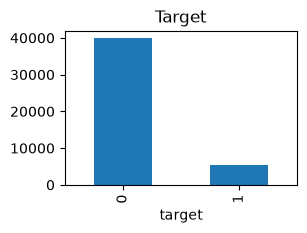

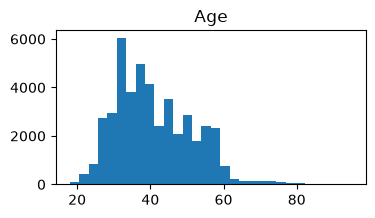

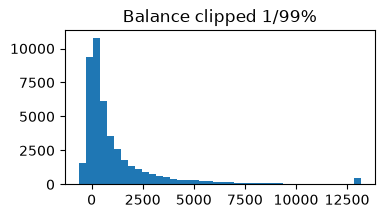

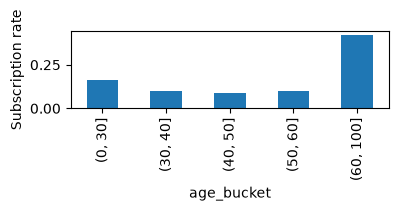

                 age   balance       day  duration  campaign     pdays  \
age         1.000000  0.097783 -0.009120 -0.004648  0.004760 -0.023758   
balance     0.097783  1.000000  0.004503  0.021560 -0.014578  0.003435   
day        -0.009120  0.004503  1.000000 -0.030206  0.162490 -0.093044   
duration   -0.004648  0.021560 -0.030206  1.000000 -0.084570 -0.001565   
campaign    0.004760 -0.014578  0.162490 -0.084570  1.000000 -0.088628   
pdays      -0.023758  0.003435 -0.093044 -0.001565 -0.088628  1.000000   
previous    0.001288  0.016674 -0.051710  0.001203 -0.032855  0.454820   
target      0.025155  0.052838 -0.028348  0.394521 -0.073172  0.103621   
job_mean_b  0.249373  0.101776  0.013340  0.009772 -0.003380 -0.026784   
demeaned_b  0.072781  0.994807  0.003161  0.020673 -0.014309  0.006193   

            previous    target    job_mean_b    demeaned_b  
age         0.001288  0.025155  2.493730e-01  7.278053e-02  
balance     0.016674  0.052838  1.017758e-01  9.948074e-01  
da

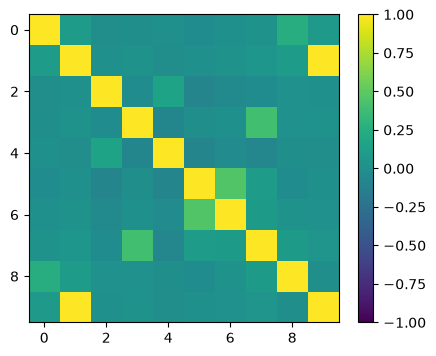

In [ ]:
fig,ax = plt.subplots(figsize=(3,2))  # plt.subplots(figsize=(a,b))
new_df["target"].value_counts().plot(kind="bar",ax=ax)  # pd NATIVE PLOTTING
ax.set_title("Target")  # set_title
plt.show()

fig,ax=plt.subplots(figsize=(4,2))
ax.hist(df["age"],bins=30)  # ax.hist(df['col'], bins=a)
ax.set_title("Age")
plt.show()

fig,ax=plt.subplots(figsize=(4,2))
lo,hi=df["balance"].quantile([.01,.99])  # clipping quantiles
ax.hist(df["balance"].clip(lo,hi),bins=40)  
ax.set_title("Balance clipped 1/99%")
plt.show()

new_df["age_bucket"]=pd.cut(new_df["age"],bins=[0,30,40,50,60,100])
fig,ax = plt.subplots(figsize=(4,2))
new_df.groupby("age_bucket",observed=True)["target"].mean().plot(kind="bar") 
plt.ylabel("Subscription rate")
plt.tight_layout()
plt.show()

corr=new_df.select_dtypes(include=np.number).corr()  # corr between ALL numerical features
print(corr)
fig,ax=plt.subplots(figsize=(5,4))
im=ax.imshow(corr,vmin=-1,vmax=1,aspect="auto")
fig.colorbar(im,ax=ax)
plt.show()

## J. 15-minute no-reference drill
Restart kernel and repeat: load → audit → conditional count → groupby → merge → plot → cyclic feature.